# Figure 5: Cumulative replacement-capacity requirements

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

In [2]:
# ---
# Configuration
# ---

REFERENCE_CAPACITY_MW = 1.0

# Replacement-cycle treatment:
# continuous = reference life / replacement life
# discrete = ceil(reference life / replacement life)
LIFETIME_MODE = "continuous"

region_order = ["Global", "China", "EU", "India", "US"]

In [3]:
# ---
# Reference cases
# ---

reference_cases = {
    "Coal": {
        "life_years": 56,
        "capacity_factor": {
            "Global": 0.55,
            "China": 0.50,
            "EU": 0.25,
            "India": 0.75,
            "US": 0.45,
        },
        "replacement_techs": [
            "Solar PV",
            "Wind Onshore",
            "Wind Offshore",
            "Nuclear",
        ],
        "panel_title": "Coal",
    },
    "Natural gas": {
        "life_years": 44,
        "capacity_factor": {
            "Global": 0.39,
            "China": 0.30,
            "EU": 0.15,
            "India": 0.30,
            "US": 0.60,
        },
        "replacement_techs": [
            "Solar PV",
            "Wind Onshore",
            "Wind Offshore",
            "Nuclear",
        ],
        "panel_title": "Natural gas",
    },
    "Nuclear": {
        "life_years": 31,
        "capacity_factor": {
            "Global": 0.81,
            "China": 0.75,
            "EU": 0.75,
            "India": 0.80,
            "US": 0.90,
        },
        "replacement_techs": [
            "Solar PV",
            "Wind Onshore",
            "Wind Offshore",
        ],
        "panel_title": "Nuclear",
    },
}


# ---
# Replacement technology parameters
# ---

capacity_factor_dict = {
    "Solar PV": {
        "Global": 0.17,
        "China": 0.12,
        "EU": 0.14,
        "India": 0.20,
        "US": 0.20,
    },
    "Wind Onshore": {
        "Global": 0.34,
        "China": 0.23,
        "EU": 0.29,
        "India": 0.27,
        "US": 0.42,
    },
    "Wind Offshore": {
        "Global": 0.42,
        "China": 0.30,
        "EU": 0.50,
        "India": 0.34,
        "US": 0.41,
    },
    "Nuclear": {
        "Global": 0.81,
        "China": 0.75,
        "EU": 0.75,
        "India": 0.80,
        "US": 0.90,
    },
}

lifespan_dict = {
    "Solar PV": {
        "observed": 8,
        "technical": 28,
    },
    "Wind Onshore": {
        "observed": 15,
        "technical": 30,
    },
    "Wind Offshore": {
        "observed": 22,
        "technical": 28,
    },
    "Nuclear": {
        "observed": 31,
        "technical": 55,
    },
}

In [4]:
# ---
# Calculation functions
# ---

# Return the number of replacement cycles over the reference lifespan.
def get_cycle_multiplier(
    reference_life,
    replacement_life,
    mode="continuous",
):
    if mode == "continuous":
        return reference_life / replacement_life

    if mode == "discrete":
        return np.ceil(reference_life / replacement_life)

    raise ValueError("mode must be 'continuous' or 'discrete'")


# Calculate cumulative replacement capacity for one reference case.
def build_replacement_dataframe(reference_name, reference_case):
    records = []

    reference_life = reference_case["life_years"]
    reference_cf_dict = reference_case["capacity_factor"]
    replacement_techs_case = reference_case["replacement_techs"]

    for region in region_order:
        reference_cf = reference_cf_dict[region]

        for tech in replacement_techs_case:
            replacement_cf = capacity_factor_dict[tech][region]
            observed_life = lifespan_dict[tech]["observed"]
            technical_life = lifespan_dict[tech]["technical"]

            # Capacity-factor correction relative to reference technology
            capacity_factor_correction = reference_cf / replacement_cf

            # Replacement cycles over reference-technology lifespan
            observed_cycles = get_cycle_multiplier(
                reference_life,
                observed_life,
                mode=LIFETIME_MODE,
            )
            technical_cycles = get_cycle_multiplier(
                reference_life,
                technical_life,
                mode=LIFETIME_MODE,
            )

            # Cumulative replacement capacity
            observed_capacity = (
                REFERENCE_CAPACITY_MW
                * capacity_factor_correction
                * observed_cycles
            )

            technical_capacity = (
                REFERENCE_CAPACITY_MW
                * capacity_factor_correction
                * technical_cycles
            )

            records.append(
                {
                    "Reference": reference_name,
                    "Region": region,
                    "Technology": tech,
                    "Reference CF": reference_cf,
                    "Replacement CF": replacement_cf,
                    "Observed lifespan": observed_life,
                    "Technical lifespan": technical_life,
                    "Observed cycles": observed_cycles,
                    "Technical cycles": technical_cycles,
                    "Observed capacity": observed_capacity,
                    "Technical capacity": technical_capacity,
                }
            )

    return pd.DataFrame(records)


# Pivot replacement capacities into plotting matrices.
def pivot_for_plotting(df_replacement):
    df_obs = (
        df_replacement.pivot(
            index="Region",
            columns="Technology",
            values="Observed capacity",
        )
        .reindex(region_order)
    )

    df_tech = (
        df_replacement.pivot(
            index="Region",
            columns="Technology",
            values="Technical capacity",
        )
        .reindex(region_order)
    )

    # Reverse order so Global appears at the top of each panel
    df_obs_vertical = df_obs.iloc[::-1].copy()
    df_tech_vertical = df_tech.iloc[::-1].copy()
    regions_vertical = df_obs_vertical.index.tolist()

    return df_obs_vertical, df_tech_vertical, regions_vertical


# ---
# Build data
# ---

case_data = {}

for reference_name, reference_case in reference_cases.items():
    df_replacement = build_replacement_dataframe(
        reference_name,
        reference_case,
    )

    (
        df_obs_vertical,
        df_tech_vertical,
        regions_vertical,
    ) = pivot_for_plotting(df_replacement)

    case_data[reference_name] = {
        "df_replacement": df_replacement,
        "df_obs_vertical": df_obs_vertical,
        "df_tech_vertical": df_tech_vertical,
        "regions_vertical": regions_vertical,
    }


# ---
# Common x-axis scale
# ---

all_values = []

for reference_name in reference_cases:
    all_values.extend(
        case_data[reference_name]["df_obs_vertical"]
        .to_numpy()
        .ravel()
    )

    all_values.extend(
        case_data[reference_name]["df_tech_vertical"]
        .to_numpy()
        .ravel()
    )

xmax_global = np.nanmax(all_values)
x_offset_global = xmax_global * 0.012


In [5]:
# ---
# Figure style
# ---

FONT_BASE = 10.0
FONT_TICKS = 10.0
FONT_REGION = 10.2
FONT_VALUE_TECHNICAL = 10.0
FONT_VALUE_OBSERVED = 10.0
FONT_PANEL = 11.0
FONT_PANEL_TITLE = 11.2
FONT_AXIS_LABEL = 11.5
FONT_LEGEND = 10.0

plt.rcParams.update(
    {
        "font.family": "Arial",
        "font.size": FONT_BASE,
        "axes.linewidth": 0.70,
        "axes.labelsize": FONT_AXIS_LABEL,
        "xtick.labelsize": FONT_TICKS,
        "ytick.labelsize": FONT_REGION,
        "legend.fontsize": FONT_LEGEND,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "savefig.dpi": 600,
    }
)

tech_colors = {
    "Solar PV": "#D9B642",
    "Wind Onshore": "#4F9AB8",
    "Wind Offshore": "#3F708F",
    "Nuclear": "#72AAA4",
}

ALPHA_TECHNICAL = 0.90
ALPHA_OBSERVED = 0.28

COLOR_TEXT = "#222222"
COLOR_GRID = "#BFBFBF"
COLOR_AXIS = "#444444"
COLOR_BACKGROUND = "white"
COLOR_REFERENCE = "#555555"

BAR_EDGE = "none"
BAR_EDGE_WIDTH = 0

BAR_HEIGHT = 0.40
TECH_OFFSET_STEP = 0.45
REGION_SPACING = 2.15

In [6]:
# ---
# Plotting function
# ---

# Plot one reference-technology replacement-capacity panel.
def plot_replacement_panel(ax, reference_name, panel_label):
    df_obs_vertical = case_data[reference_name]["df_obs_vertical"]
    df_tech_vertical = case_data[reference_name]["df_tech_vertical"]
    regions_vertical = case_data[reference_name]["regions_vertical"]

    replacement_techs_case = reference_cases[
        reference_name
    ]["replacement_techs"]

    # Centre technology bars around each regional position
    tech_offsets_case = dict(
        zip(
            replacement_techs_case,
            (
                np.arange(len(replacement_techs_case))
                - (len(replacement_techs_case) - 1) / 2
            )
            * TECH_OFFSET_STEP,
        )
    )

    y_centers = (
        np.arange(len(regions_vertical))
        * REGION_SPACING
    )

    # Bars and value annotations
    for i, region in enumerate(regions_vertical):
        y_center = y_centers[i]

        for tech in replacement_techs_case:
            observed_value = df_obs_vertical.loc[region, tech]
            technical_value = df_tech_vertical.loc[region, tech]

            y = y_center + tech_offsets_case[tech]
            color = tech_colors[tech]

            if observed_value >= technical_value:
                # Technical requirement
                ax.barh(
                    y,
                    technical_value,
                    height=BAR_HEIGHT,
                    color=color,
                    alpha=ALPHA_TECHNICAL,
                    edgecolor=BAR_EDGE,
                    linewidth=BAR_EDGE_WIDTH,
                    zorder=3,
                )

                # Additional requirement from observed lifespan
                ax.barh(
                    y,
                    observed_value - technical_value,
                    left=technical_value,
                    height=BAR_HEIGHT,
                    color=color,
                    alpha=ALPHA_OBSERVED,
                    edgecolor=BAR_EDGE,
                    linewidth=BAR_EDGE_WIDTH,
                    zorder=3,
                )

            else:
                # Fallback when technical requirement exceeds observed
                ax.barh(
                    y,
                    observed_value,
                    height=BAR_HEIGHT,
                    color=color,
                    alpha=ALPHA_OBSERVED,
                    edgecolor=BAR_EDGE,
                    linewidth=BAR_EDGE_WIDTH,
                    zorder=3,
                )

                ax.barh(
                    y,
                    technical_value - observed_value,
                    left=observed_value,
                    height=BAR_HEIGHT,
                    color=color,
                    alpha=ALPHA_TECHNICAL,
                    edgecolor=BAR_EDGE,
                    linewidth=BAR_EDGE_WIDTH,
                    zorder=3,
                )

            # Technical requirement label
            technical_label_x = (
                technical_value
                - x_offset_global * 0.35
            )

            if technical_label_x <= 0:
                technical_label_x = technical_value * 0.55

            ax.text(
                technical_label_x,
                y,
                f"{technical_value:.1f}",
                va="center",
                ha="right",
                fontsize=FONT_VALUE_TECHNICAL,
                fontweight="normal",
                color=COLOR_TEXT,
                zorder=6,
            )

            # Total requirement using observed lifespan
            ax.text(
                observed_value + x_offset_global,
                y,
                f"{observed_value:.1f}",
                va="center",
                ha="left",
                fontsize=FONT_VALUE_OBSERVED,
                fontweight="bold",
                color=COLOR_TEXT,
                zorder=7,
            )

    # Y axis
    ax.set_yticks(y_centers)

    ax.set_yticklabels(
        regions_vertical,
        fontsize=FONT_REGION,
        fontweight="normal",
        color=COLOR_TEXT,
    )

    ax.set_ylabel("")

    # Axis limits
    ax.set_xlim(
        0,
        xmax_global * 1.18,
    )

    ax.set_ylim(
        y_centers.min() - 1.10,
        y_centers.max() + 1.10,
    )

    # One-to-one nameplate-capacity reference
    ax.axvline(
        1,
        color=COLOR_REFERENCE,
        linestyle="--",
        linewidth=0.95,
        alpha=0.85,
        zorder=2,
    )

    # Grid and spines
    ax.grid(
        axis="x",
        color=COLOR_GRID,
        linewidth=0.45,
        linestyle="-",
        alpha=0.30,
        zorder=0,
    )

    ax.grid(
        axis="y",
        visible=False,
    )

    ax.set_axisbelow(True)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.spines["bottom"].set_color(COLOR_AXIS)
    ax.spines["bottom"].set_linewidth(0.70)

    # Ticks
    ax.tick_params(
        axis="y",
        length=0,
        colors=COLOR_TEXT,
        labelsize=FONT_REGION,
        pad=10,
    )

    ax.tick_params(
        axis="x",
        direction="out",
        length=3.0,
        width=0.70,
        colors=COLOR_TEXT,
        labelsize=FONT_TICKS,
        pad=3,
    )

    # Panel label and title
    ax.text(
        -0.105,
        1.05,
        panel_label,
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=FONT_PANEL,
        fontweight="bold",
        color=COLOR_TEXT,
    )

    ax.text(
        0.00,
        1.05,
        reference_cases[reference_name]["panel_title"],
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=FONT_PANEL_TITLE,
        fontweight="bold",
        color=COLOR_TEXT,
    )


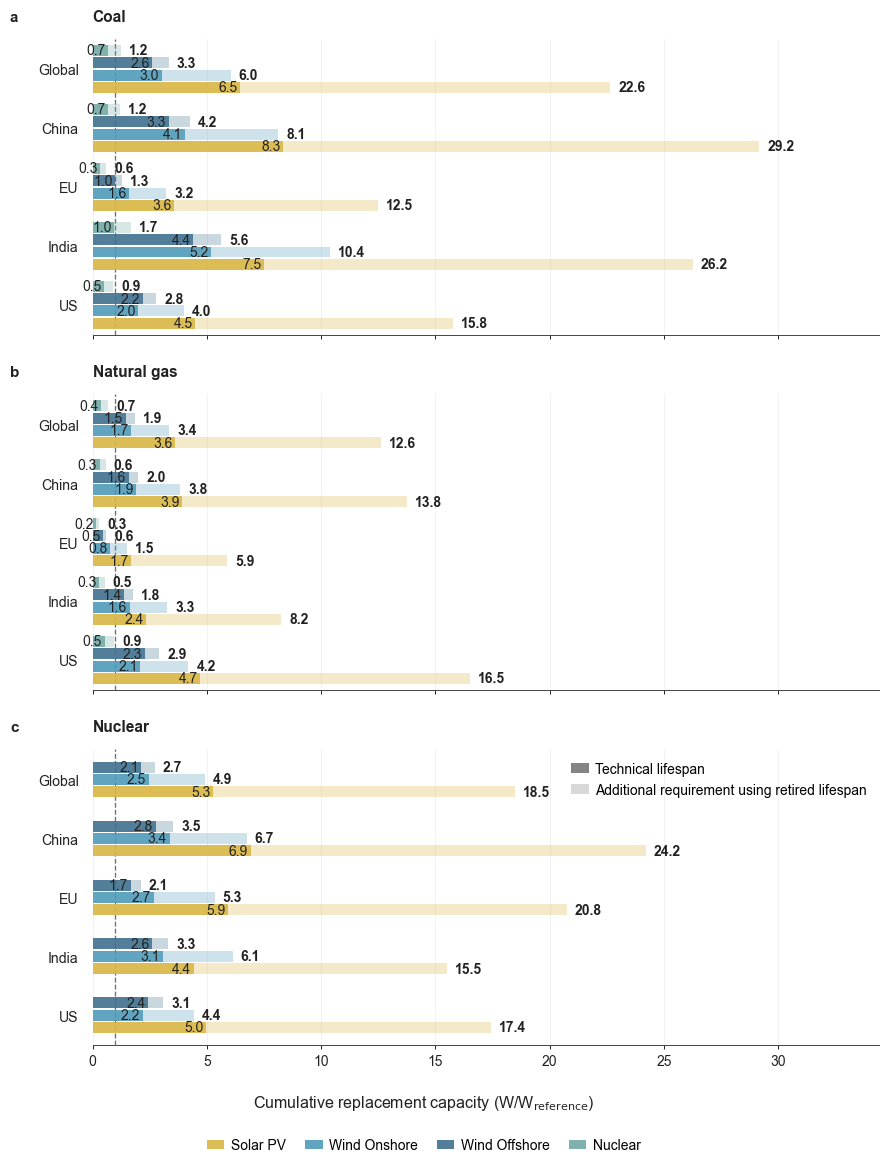

In [7]:
# ---
# Figure
# ---

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(9.2, 12.2),
    sharex=True,
)

fig.patch.set_facecolor(COLOR_BACKGROUND)

for ax in axes:
    ax.set_facecolor(COLOR_BACKGROUND)

plot_replacement_panel(
    axes[0],
    reference_name="Coal",
    panel_label="a",
)

plot_replacement_panel(
    axes[1],
    reference_name="Natural gas",
    panel_label="b",
)

plot_replacement_panel(
    axes[2],
    reference_name="Nuclear",
    panel_label="c",
)


# ---
# Common x-axis label
# ---

fig.supxlabel(
    r"Cumulative replacement capacity (W/W$_{\mathrm{reference}}$)",
    fontsize=FONT_AXIS_LABEL,
    fontweight="normal",
    y=0.085,
    color=COLOR_TEXT,
)


# ---
# Legends
# ---

legend_techs = [
    "Solar PV",
    "Wind Onshore",
    "Wind Offshore",
    "Nuclear",
]

tech_legend_elements = [
    Patch(
        facecolor=tech_colors[tech],
        edgecolor="none",
        alpha=ALPHA_TECHNICAL,
        label=tech,
    )
    for tech in legend_techs
]

fig.legend(
    handles=tech_legend_elements,
    frameon=False,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.042),
    fontsize=FONT_LEGEND,
    ncol=4,
    columnspacing=1.40,
    handlelength=1.25,
    handletextpad=0.45,
)

requirement_legend = [
    Patch(
        facecolor="#777777",
        alpha=ALPHA_TECHNICAL,
        edgecolor="none",
        label="Technical lifespan",
    ),
    Patch(
        facecolor="#777777",
        alpha=ALPHA_OBSERVED,
        edgecolor="none",
        label="Additional requirement using retired lifespan",
    ),
]

axes[2].legend(
    handles=requirement_legend,
    frameon=False,
    loc="upper right",
    fontsize=FONT_LEGEND,
    handlelength=1.25,
    handletextpad=0.45,
)


# ---
# Layout and export
# ---

fig.subplots_adjust(
    left=0.14,
    right=0.995,
    top=0.965,
    bottom=0.14,
    hspace=0.20,
)


plt.savefig(
    "figures/main/figure-5.png",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)

plt.savefig(
    "figures/main/figure-5.pdf",
    bbox_inches="tight",
    transparent=True,
)

plt.show()